In [1]:
import config.const
from src.tools.load_model import *

tokenizer, model , bert_tokenizer, bert_model = load_model(with_bert=True)

system check:
Python path: /usr/local/bin/python3.12
Torch version: 2.14.1+cu130
GPU: NVIDIA GeForce RTX 5060 Ti
PyTorch: 2.14.1+cu130
CUDA: 13.0
CUDA available: True
Capability: (12, 0)
this is include the following functions torch , torch.nn.functional as F, transformers.AutoTokenizer, transformers.AutoModelForCausalLM


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [2]:
from src.tools.embeddings import *
from src.tools.wordnet import *

In [3]:
def get_top_probs(top_probs, top_indices, tokenizer, stop_words):
    valid_words = []
    valid_probs = []
    seen = set()
    
    for prob, idx in zip(top_probs, top_indices):
        word = tokenizer.decode(idx.item()).strip()
        clean_predicted_word = "".join([c for c in word if c.isalpha()]).lower()
        # check_word = word.lower()

        if not clean_predicted_word or clean_predicted_word in stop_words:
            continue

        if clean_predicted_word in seen: # " science" and "Science" -> keep only the first
            continue
            
        # if any(c.isalpha() for c in word) and check_word not in stop_words:
        seen.add(clean_predicted_word)
        
        valid_words.append(word)
        valid_probs.append(prob.item())
        
        if len(valid_words) == 5:
            break
        
    return valid_words, valid_probs

In [4]:
import re

def check_special_symbols(target_symbols: str, next_word: str = "") -> bool:
    cleaned_word = target_symbols.rstrip('"\')]}')
    if not cleaned_word:
        return False
        
    last_symbol = cleaned_word[-1]
    if last_symbol in ("!", "?"):
        return True
        
    last_symbol = cleaned_word[-1] if cleaned_word else ""

    if last_symbol == ".":
        lower_word = cleaned_word.lower()

        # 2. ראשי תיבות מרובי-נקודות כמו U.S. או Ph.D.
        if re.fullmatch(r"(?:[A-Za-z]\.){2,}", cleaned_word):
            return False

        # 3. אות בודדת עם נקודה (J., M.) או קיצור שם קצר (Th.) כשלאחריו מגיעה אות גדולה
        # למשל: "Piek Th. J. M. Vossen" -> ממשיך; אבל "end of sentence. Next" -> חותך
        stem = cleaned_word[:-1]
        if len(stem) <= 2 and stem.isalpha() and stem[0].isupper():
            # אם המילה הבאה מתחילה באות גדולה, זה כנראה המשך של שם/ראשי תיבות (כמו Th. J. או M. Vossen)
            if next_word and next_word[0].isupper():
                return False

        return True
       
    return False

In [5]:
import numpy as np
import pandas as pd

# every signal measured at each word; each one becomes a column of the CSV and a curve for the clustering
COSINE_SIGNALS = {
    "mean_cos": "mean cosine over all pairs of the top-5 guesses",
    "weighted_cos": "pair cosines weighted by the two guesses' probabilities",
    "top1_cos": "mean cosine of the #1 guess to the other guesses",
    "min_cos": "cosine of the least similar pair of guesses",
    "max_cos": "cosine of the most similar pair of guesses",
    "top1_prob": "probability of the #1 guess (model confidence, no BERT)",
}


def cosine_signals(cos_matrix, probs, decimals=4):
    """Every signal of one measured word, from the guesses' cosine matrix and probabilities.
    The cosine signals are None when there are fewer than 2 guesses (no pair to compare)."""
    values = {key: None for key in COSINE_SIGNALS}
    if probs:
        values["top1_prob"] = round(float(probs[0]), 6)
    if cos_matrix is None or cos_matrix.shape[0] < 2:
        return values
    matrix = cos_matrix.detach().float().cpu().numpy()
    n = matrix.shape[0]
    off_diag = ~np.eye(n, dtype=bool)
    pairs = matrix[off_diag]
    weights = np.asarray(probs[:n], dtype=float)
    pair_weights = np.outer(weights, weights)[off_diag]
    values["mean_cos"] = round(float(pairs.mean()), decimals)
    values["weighted_cos"] = round(float((pairs * pair_weights).sum() / pair_weights.sum()), decimals)
    values["top1_cos"] = round(float(matrix[0, 1:].mean()), decimals)
    values["min_cos"] = round(float(pairs.min()), decimals)
    values["max_cos"] = round(float(pairs.max()), decimals)
    return values


def pair_cosines_text(cos_matrix, words, decimals=2):
    """'a-b:0.53 a-c:0.41 ...': every pair of guesses once."""
    if cos_matrix is None:
        return ""
    parts = []
    for i in range(len(words)):
        for j in range(i + 1, len(words)):
            parts.append(f"{words[i]}-{words[j]}:{cos_matrix[i, j].item():.{decimals}f}")
    return " ".join(parts)


def analyze_block_cosine(
    text,
    model,
    tokenizer,
    bert_model,
    bert_tokenizer,
    print_results: bool = False,
):
    """At every measured word (not a stop word): the model's top-5 guesses for it, and how similar the guesses
    are to each other (BERT cosine). The context restarts after every sentence end (a block).

    Returns (context_blocks, blocks_cosine_result, word_table):
        blocks_cosine_result  {'block1': [mean cos, ...], ...}, the input of plot_curve
        word_table            one row per measured word with every signal of COSINE_SIGNALS (saved as CSV)
    """
    stop_words = get_stopwords()
    words = text.split()
    context_start_idx = 0
    context_blocks = []
    blocks_cosine_result = {}
    rows = []

    for i, current_next_word in enumerate(words):
        context_words = words[context_start_idx:i]

        clean_target_word = "".join(c for c in current_next_word if c.isalpha()).lower()

        if context_words and clean_target_word and clean_target_word not in stop_words:
            context_str = " ".join(context_words)
            batch = tokenizer(context_str, return_tensors="pt").to(model.device)

            with torch.no_grad():
                outputs = model(**batch)
                logits = outputs.logits[0, -1, :]
                top_probs, top_indices = torch.topk(F.softmax(logits, dim=-1), 100)
                valid_words, valid_probs = get_top_probs(top_probs, top_indices, tokenizer, stop_words)

                cos_matrix, mean_cos = check_cosine_similarity(
                    words=valid_words,
                    bert_tokenizer=bert_tokenizer,
                    bert_model=bert_model,
                    context_str=context_str,
                    target_word=current_next_word,
                    plot=False,  # אופציונלי: למנוע פתיחת עשרות heatmaps אם יש הרבה מילים
                    print_table=print_results,
                )

            block_number = len(context_blocks) + 1
            blocks_cosine_result.setdefault(f"block{block_number}", []).append(mean_cos)

            candidates = ["".join(c for c in w if c.isalpha()).lower() or w.strip() for w in valid_words]
            signals = cosine_signals(cos_matrix, valid_probs)
            signals["mean_cos"] = mean_cos          # exactly the value check_cosine_similarity gives
            rows.append({
                "word_idx": i,
                "block": block_number,
                "word": current_next_word,
                "context": context_str,
                "candidates": " ".join(candidates),
                "candidate_probs": " ".join(f"{p:.6g}" for p in valid_probs),
                "pair_cosines": pair_cosines_text(cos_matrix, candidates),
                **signals,
            })

        #check special_symbols
        next_word = words[i + 1] if i + 1 < len(words) else ""
        if check_special_symbols(current_next_word, next_word):
            block = " ".join(words[context_start_idx : i + 1])
            context_blocks.append(block)
            if print_results:
                print(f"Block {len(context_blocks)}: {block}\n")
            context_start_idx = i + 1

    columns = ["word_idx", "block", "word", "context", "candidates", "candidate_probs", "pair_cosines",
               *COSINE_SIGNALS]
    word_table = pd.DataFrame(rows, columns=columns)
    return context_blocks, blocks_cosine_result, word_table

In [6]:
def check_cosine_similarity(
    words: list[str],
    bert_tokenizer,
    bert_model,
    context_str: str = "",
    target_word: str = "",
    decimals: int = 4,
    plot: bool = True,
    print_table: bool = True,
):
    if not words:
        return None, None

    clean_words = ["".join(c for c in w if c.isalpha()).lower() or w for w in words]
    labels = [f"{idx}:{cw}" for idx, cw in enumerate(clean_words)]

    vectors = [
        get_bert_vec(cw, bert_tokenizer, bert_model).detach().float().cpu()
        for cw in clean_words
    ]
    emb_matrix = torch.stack(vectors)  # (N, D)
    norm_emb = F.normalize(emb_matrix, p=2, dim=-1)
    cos_matrix = torch.mm(norm_emb, norm_emb.t())  # (N, N)

    # ממוצע של כל הזוגות השונים (ללא האלכסון הראשי של 1.0)
    n = cos_matrix.shape[0]
    if n > 1:
        off_diag_mask = ~torch.eye(n, dtype=torch.bool)
        mean_cos = round(cos_matrix[off_diag_mask].mean().item(), decimals)
    else:
        mean_cos = None

    if print_table:
        if context_str or target_word:
            print(f"\nContext: '{context_str}' | Target: '{target_word}' | Mean Cos: {mean_cos}")

        col_width = max(10, max(len(lbl) for lbl in labels) + 2)
        row_width = max(12, max(len(lbl) for lbl in labels) + 2)
        header = f"{'Top-5':<{row_width}} | " + " | ".join(f"{lbl:>{col_width}}" for lbl in labels)
        print(header)
        print("-" * len(header))

        for i, row_lbl in enumerate(labels):
            vals = [f"{cos_matrix[i, j].item():>{col_width}.{decimals}f}" for j in range(n)]
            print(f"{row_lbl:<{row_width}} | " + " | ".join(vals))

    if plot:
        title = f"Target: '{target_word}'" if target_word else "Top-5 Cosine Similarity"
        plot_mini_heatmap(cos_matrix, labels, title=title, decimals=2)

    return cos_matrix, mean_cos

In [7]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


def plot_mini_heatmap(cos_matrix: torch.Tensor, labels: list[str], title: str = "", decimals: int = 2):
    matrix_np = cos_matrix.detach().cpu().numpy()
    n = matrix_np.shape[0]

    fig, ax = plt.subplots(figsize=(4.2, 3.5), dpi=100)
    im = ax.imshow(matrix_np, vmin=-1.0, vmax=1.0, cmap="coolwarm")

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

    for i in range(n):
        for j in range(n):
            val = matrix_np[i, j]
            text_color = "white" if abs(val) > 0.65 else "black"
            ax.text(j, i, f"{val:.{decimals}f}", ha="center", va="center", color=text_color, fontsize=7.5)

    if title:
        ax.set_title(title, fontsize=9, pad=8)

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

In [8]:
import math
import numpy as np
import matplotlib.pyplot as plt


def plot_curve(
    heights,
    title="Cosine Similarity",
    blocks_per_row=15,
    show_values=False,
    figsize_per_row=(16, 3.0),
    decimals=2,
):
    """מציג ערכי Cosine (בטווח 0 עד 1) בחלוקה נוחה לשורות כדי למנוע צפיפות ודריסת תוויות."""
    if not isinstance(heights, dict):
        heights = {"block1": heights}

    # סינון בלוקים ריקים
    valid_blocks = [
        (name, [np.nan if h is None else float(h) for h in vals])
        for name, vals in heights.items()
        if vals
    ]

    if not valid_blocks:
        print("No valid data to plot.")
        return None

    num_blocks = len(valid_blocks)
    num_rows = math.ceil(num_blocks / blocks_per_row)

    fig, axes = plt.subplots(
        num_rows,
        1,
        figsize=(figsize_per_row[0], figsize_per_row[1] * num_rows),
        squeeze=False,
    )
    colors = plt.cm.tab10.colors

    # סקאלה קבועה בין 0 ל-1 (עם מרווח קטן למעלה כדי שהמספרים מעל הנקודות לא ייחתכו)
    y_min = 0.0
    y_max = 1.12 if show_values else 1.05

    global_pos = 1

    for row_idx in range(num_rows):
        ax = axes[row_idx, 0]
        chunk = valid_blocks[row_idx * blocks_per_row : (row_idx + 1) * blocks_per_row]
        row_start_pos = global_pos

        for idx_in_chunk, (block_name, values) in enumerate(chunk):
            block_idx = row_idx * blocks_per_row + idx_in_chunk
            color = colors[block_idx % len(colors)]
            positions = np.arange(global_pos, global_pos + len(values))

            # רקע עדין לבלוק
            ax.axvspan(positions[0] - 0.5, positions[-1] + 0.5, color=color, alpha=0.10, lw=0)

            # קו ונקודות
            ax.plot(positions, values, color=color, lw=1.6, marker="o", ms=4.5)

            # הצגת המספר (2 ספרות אחרי הנקודה) מעל כל נקודה אם מופעל
            if show_values:
                for x, y in zip(positions, values):
                    if not np.isnan(y):
                        ax.text(
                            x,
                            y + 0.025,
                            f"{y:.{decimals}f}",
                            ha="center",
                            va="bottom",
                            fontsize=7.5,
                            color="#333333",
                        )

            # קו הפרדה בין בלוקים
            if idx_in_chunk > 0:
                ax.axvline(positions[0] - 0.5, color=color, ls="--", lw=0.9, alpha=0.7)

            # הצגת שם הבלוק רק אם יש מספיק מקום (לפחות 2 מילים) או עם הטיה קלה
            if block_name:
                label = block_name.replace("block", "B")
                rotation = 0 if len(values) >= 3 else 45
                ax.text(
                    (positions[0] + positions[-1]) / 2,
                    1.02,
                    label,
                    transform=ax.get_xaxis_transform(),
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    fontweight="bold",
                    color=color,
                    rotation=rotation,
                )

            global_pos += len(values)

        ax.set_xlim(row_start_pos - 0.5, global_pos - 0.5)
        ax.set_ylim(y_min, y_max)
        ax.set_yticks(np.linspace(0.0, 1.0, 6))  # 0.0, 0.2, 0.4, 0.6, 0.8, 1.0
        ax.set_yticklabels([f"{t:.{decimals}f}" for t in np.linspace(0.0, 1.0, 6)])
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.set_ylabel("Mean cosine", fontsize=9)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if row_idx == 0:
            ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=22)

    axes[-1, 0].set_xlabel("Measured word index (in reading order)", fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

In [9]:
# Saving / loading the results: one CSV per text in src/Results_CSV/cosine, one row per measured word.
# Columns: word_idx, block, word, context, candidates, candidate_probs, pair_cosines, then one column per signal.
from pathlib import Path
from IPython.display import display

TEXTS_DIR = Path("./texts_data")
RESULTS_DIR = Path.cwd().parent / "Results_CSV" / "cosine"     # this notebook runs from src/note_books
MODEL_TAG = model.name_or_path.replace("/", "_")               # e.g. Qwen_Qwen2.5-7B-Instruct, as in Results_CSV


def results_path(text_name):
    return RESULTS_DIR / f"{MODEL_TAG}__{text_name}.csv"


def save_word_table(text_name, word_table):
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    path = results_path(text_name)
    word_table.to_csv(path, index=False)
    return path


def load_word_table(text_name):
    """A saved text's table (only empty cells are read as missing, so a word like 'null' stays a word)."""
    return pd.read_csv(results_path(text_name), keep_default_na=False, na_values=[""])


def signal_curve(word_table, column="mean_cos"):
    """One text's curve of a signal: its values in reading order, missing values skipped. The cluster input."""
    values = pd.to_numeric(word_table[column], errors="coerce").to_numpy(dtype=float)
    return values[~np.isnan(values)]


def blocks_from_table(word_table, column="mean_cos"):
    """{'block1': [...], ...} rebuilt from a saved table. The plot_curve input."""
    blocks = {}
    for block_number, values in word_table.groupby("block", sort=True)[column]:
        blocks[f"block{block_number}"] = [None if pd.isna(v) else float(v) for v in values]
    return blocks


def plot_signals(word_table, title=""):
    """Every signal's curve of one text, one panel each, same x-axis."""
    fig, axes = plt.subplots(len(COSINE_SIGNALS), 1, figsize=(16, 1.7 * len(COSINE_SIGNALS)), sharex=True)
    for ax, (column, description) in zip(axes, COSINE_SIGNALS.items()):
        values = pd.to_numeric(word_table[column], errors="coerce")
        ax.plot(np.arange(1, len(values) + 1), values, lw=1.1, marker="o", ms=2.5)
        ax.set_title(f"{column}: {description}   (mean {values.mean():.3f}, std {values.std():.3f})",
                     loc="left", fontsize=9)
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    axes[-1].set_xlabel("Measured word index (in reading order)", fontsize=10)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    plt.show()


def show_word_table(word_table):
    """Each signal's summary over the text, then every measured word with its guesses and signals."""
    display(word_table[list(COSINE_SIGNALS)].describe().loc[["count", "mean", "std", "min", "max"]].round(3))
    with pd.option_context("display.max_colwidth", 70, "display.max_rows", 500):
        display(word_table.drop(columns=["context"]))


def run_text(text_name, texts_dir=TEXTS_DIR, print_results=True):
    """Measure one text, save its CSV, show its table and curves.
    Returns (context_blocks, blocks_cosine_result, word_table)."""
    content = (Path(texts_dir) / f"{text_name}.txt").read_text(encoding="utf-8")
    print(content, "\n")
    context_blocks, blocks_cosine_result, word_table = analyze_block_cosine(
        content,
        model=model,
        tokenizer=tokenizer,
        bert_model=bert_model,
        bert_tokenizer=bert_tokenizer,
        print_results=print_results,
    )
    path = save_word_table(text_name, word_table)
    print(f"saved {len(word_table)} measured words -> {path}")
    show_word_table(word_table)
    plot_curve(blocks_cosine_result, title=f"{text_name}: mean cosine per block", blocks_per_row=12, show_values=True)
    plot_signals(word_table, title=f"{text_name}: every signal")
    return context_blocks, blocks_cosine_result, word_table

Computer science is the study of computation, information, and automation.
Computer science spans theoretical disciplines (such as algorithms, theory of computation, and information theory) to applied disciplines (including the design and implementation of hardware and software).
Computer science is generally considered an area of academic research and distinct from computer programming. 


Context: 'Computer' | Target: 'science' | Mean Cos: 0.6029
Top-5        |    0:science |   1:software |   2:graphics |     3:vision |     4:memory
---------------------------------------------------------------------------------------
0:science    |       1.0000 |       0.5609 |       0.5013 |       0.5255 |       0.5749
1:software   |       0.5609 |       1.0000 |       0.6474 |       0.6912 |       0.6670
2:graphics   |       0.5013 |       0.6474 |       1.0000 |       0.5171 |       0.5423
3:vision     |       0.5255 |       0.6912 |       0.5171 |       1.0000 |       0.8018
4:memory     |     

,mean_cos,weighted_cos,top1_cos,min_cos,max_cos,top1_prob
count,30.000,30.000,30.000,30.000,30.000,30.000
mean,0.638,0.657,0.654,0.488,0.797,0.457
std,0.065,0.089,0.088,0.104,0.054,0.364
min,0.497,0.448,0.459,0.201,0.671,0.001
max,0.761,0.800,0.813,0.687,0.908,1.000


,word_idx,block,word,candidates,candidate_probs,pair_cosines,mean_cos,weighted_cos,top1_cos,min_cos,max_cos,top1_prob
0,1,1,science,science software graphics vision memory,0.0327148 0.0106812 0.0071106 0.00552368 0.0050354,science-software:0.56 science-graphics:0.50 science-vision:0.53 sc...,0.6029,0.5661,0.5406,0.5013,0.8018,0.032715
1,4,1,study,study scientific science systematic heart,0.519531 0.131836 0.102539 0.0167236 0.0130615,study-scientific:0.67 study-science:0.58 study-systematic:0.66 stu...,0.6010,0.6305,0.6297,0.4889,0.8075,0.519531
2,6,1,"computation,",computers information algorithms computation algorithm,0.0957031 0.0742188 0.065918 0.045166 0.0166016,computers-information:0.47 computers-algorithms:0.74 computers-com...,0.6429,0.6188,0.6306,0.4486,0.8656,0.095703
3,7,1,"information,",automation algorithms automated automat automate,0.835938 0.0119019 0.0112305 0.00769043 0.00637817,automation-algorithms:0.73 automation-automated:0.81 automation-au...,0.6293,0.6993,0.6797,0.4701,0.8053,0.835938
4,9,1,automation.,automation automated programming autom automatic,0.785156 0.136719 0.0098877 0.00872803 0.00872803,automation-automated:0.81 automation-programming:0.72 automation-a...,0.6556,0.7798,0.7015,0.5232,0.8176,0.785156
5,11,2,science,science software graphics vision memory,0.0327148 0.0106812 0.0071106 0.00552368 0.0050354,science-software:0.56 science-graphics:0.50 science-vision:0.53 sc...,0.6029,0.5661,0.5406,0.5013,0.8018,0.032715
6,12,2,spans,students professor researchers education encompasses,0.029541 0.0168457 0.0123291 0.0108643 0.00848389,students-professor:0.68 students-researchers:0.78 students-educati...,0.5821,0.6153,0.6356,0.4199,0.7753,0.029541
7,13,2,theoretical,multiple several across numerous theory,0.0288086 0.0253906 0.0174561 0.00823975 0.0072937,multiple-several:0.83 multiple-across:0.68 multiple-numerous:0.87 ...,0.7130,0.7344,0.7674,0.5757,0.8745,0.028809
8,14,2,disciplines,foundations studies concepts computer fields,0.0795898 0.0375977 0.0332031 0.0292969 0.0201416,foundations-studies:0.84 foundations-concepts:0.85 foundations-com...,0.7454,0.7669,0.7824,0.6343,0.8522,0.079590
9,17,2,"algorithms,",algorithms computational comput theory algorithm,0.699219 0.0947266 0.0307617 0.0239258 0.0145264,algorithms-computational:0.65 algorithms-comput:0.56 algorithms-th...,0.6623,0.6618,0.6969,0.5552,0.8656,0.699219


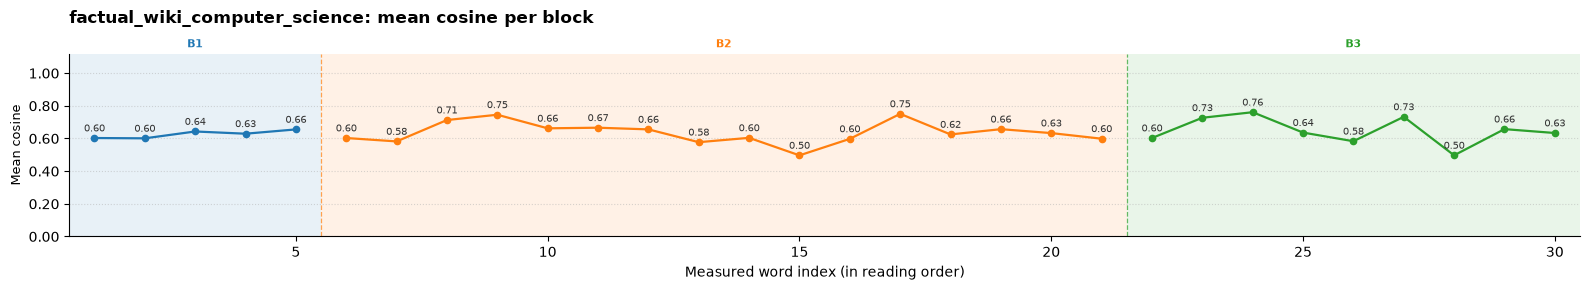

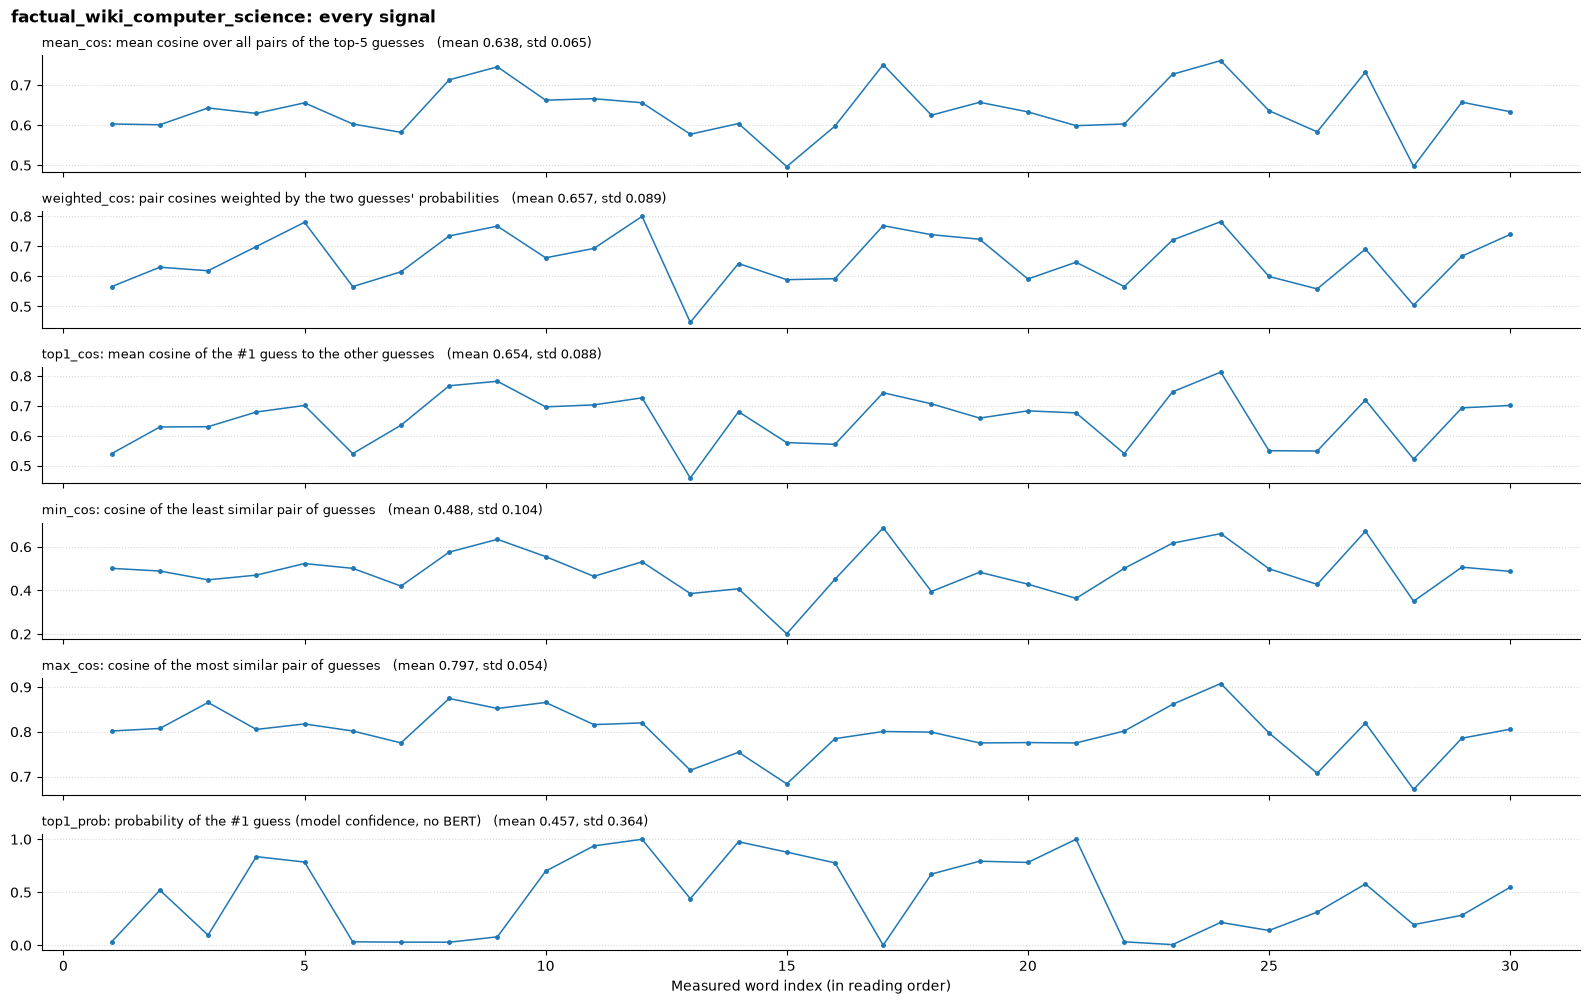

In [10]:
context_blocks, blocks_cosine_result, word_table = run_text("factual_wiki_computer_science")

WordNet is a lexical database of semantic relations between words that links words into semantic relations including synonyms, hyponyms, and meronyms. The synonyms are grouped into synsets with short definitions and usage examples. It can thus be seen as a combination and extension of a dictionary and thesaurus. Its primary use is in automatic text analysis and artificial intelligence applications. It was first created in the English language and the English WordNet database and software tools have been released under a BSD style license and are freely available for download. As of 2026, the project is no longer being developed. The online version is no longer available. Previous versions of the website described funding and staffing issues. There are several community-led projects actively maintaining a version of the dataset. Some efforts recognized by the project include the Open English Wordnet and the Global WordNet Association. WordNet was first created in 1985, in English only, 

,mean_cos,weighted_cos,top1_cos,min_cos,max_cos,top1_prob
count,345.000,345.000,345.000,345.000,345.000,345.000
mean,0.595,0.607,0.600,0.449,0.767,0.456
std,0.080,0.099,0.096,0.114,0.068,0.363
min,0.390,0.299,0.300,0.129,0.500,0.000
max,0.814,0.836,0.826,0.769,0.940,1.000


,word_idx,block,word,candidates,candidate_probs,pair_cosines,mean_cos,weighted_cos,top1_cos,min_cos,max_cos,top1_prob
0,3,1,lexical,lexical large database sem semantic,0.636719 0.181641 0.0262451 0.0131836 0.0116577,lexical-large:0.44 lexical-database:0.47 lexical-sem:0.43 lexical-...,0.5597,0.4587,0.4776,0.4307,0.7243,0.636719
1,4,1,database,database knowledge resource reference dataset,0.988281 0.00260925 0.00115967 0.000514984 0.000514984,database-knowledge:0.66 database-resource:0.75 database-reference:...,0.6051,0.6768,0.6730,0.4851,0.7528,0.988281
2,6,1,semantic,english synonyms nouns natural words,0.490234 0.0229492 0.0122681 0.0101318 0.00579834,english-synonyms:0.38 english-nouns:0.52 english-natural:0.59 engl...,0.4845,0.4730,0.5155,0.3279,0.5922,0.490234
3,7,1,relations,relations relationships domains features fields,0.800781 0.0698242 0.0273438 0.0187988 0.012146,relations-relationships:0.68 relations-domains:0.65 relations-feat...,0.6536,0.6548,0.6390,0.5818,0.7415,0.800781
4,9,1,words,words english pairs syn synonyms,0.769531 0.133789 0.0231934 0.0180664 0.0116577,words-english:0.58 words-pairs:0.40 words-syn:0.69 words-synonyms:...,0.4283,0.5454,0.4979,0.2796,0.6877,0.769531
5,11,1,links,groups provides allows captures serves,0.0289307 0.0211182 0.0211182 0.0198975 0.0186768,groups-provides:0.55 groups-allows:0.57 groups-captures:0.62 group...,0.6930,0.6750,0.5731,0.5499,0.8288,0.028931
6,12,1,words,words similar related english nouns,0.472656 0.0498047 0.0302734 0.0302734 0.0267334,words-similar:0.58 words-related:0.58 words-english:0.58 words-nou...,0.5789,0.5836,0.5833,0.5067,0.7757,0.472656
7,14,1,semantic,groups synonym syn semantic synonyms,0.0917969 0.0917969 0.0717773 0.0383301 0.0297852,groups-synonym:0.49 groups-syn:0.52 groups-semantic:0.55 groups-sy...,0.5042,0.5155,0.4865,0.2796,0.7330,0.091797
8,15,1,relations,networks relations groups sets maps,0.408203 0.192383 0.0966797 0.0625 0.0314941,networks-relations:0.68 networks-groups:0.66 networks-sets:0.54 ne...,0.6124,0.6356,0.6484,0.5013,0.7107,0.408203
9,16,1,including,called using based including via,0.0144043 0.0126953 0.0112305 0.00363159 0.00283813,called-using:0.57 called-based:0.67 called-including:0.59 called-v...,0.6069,0.6316,0.5820,0.5012,0.7440,0.014404


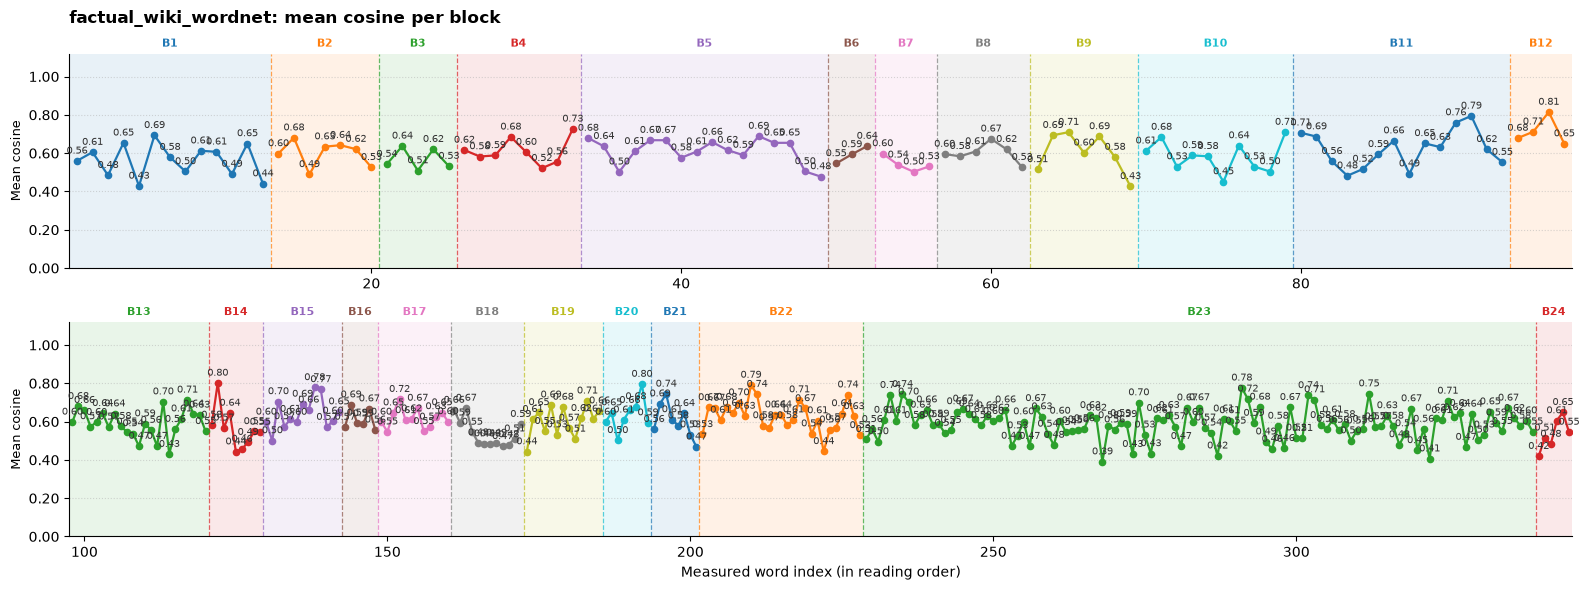

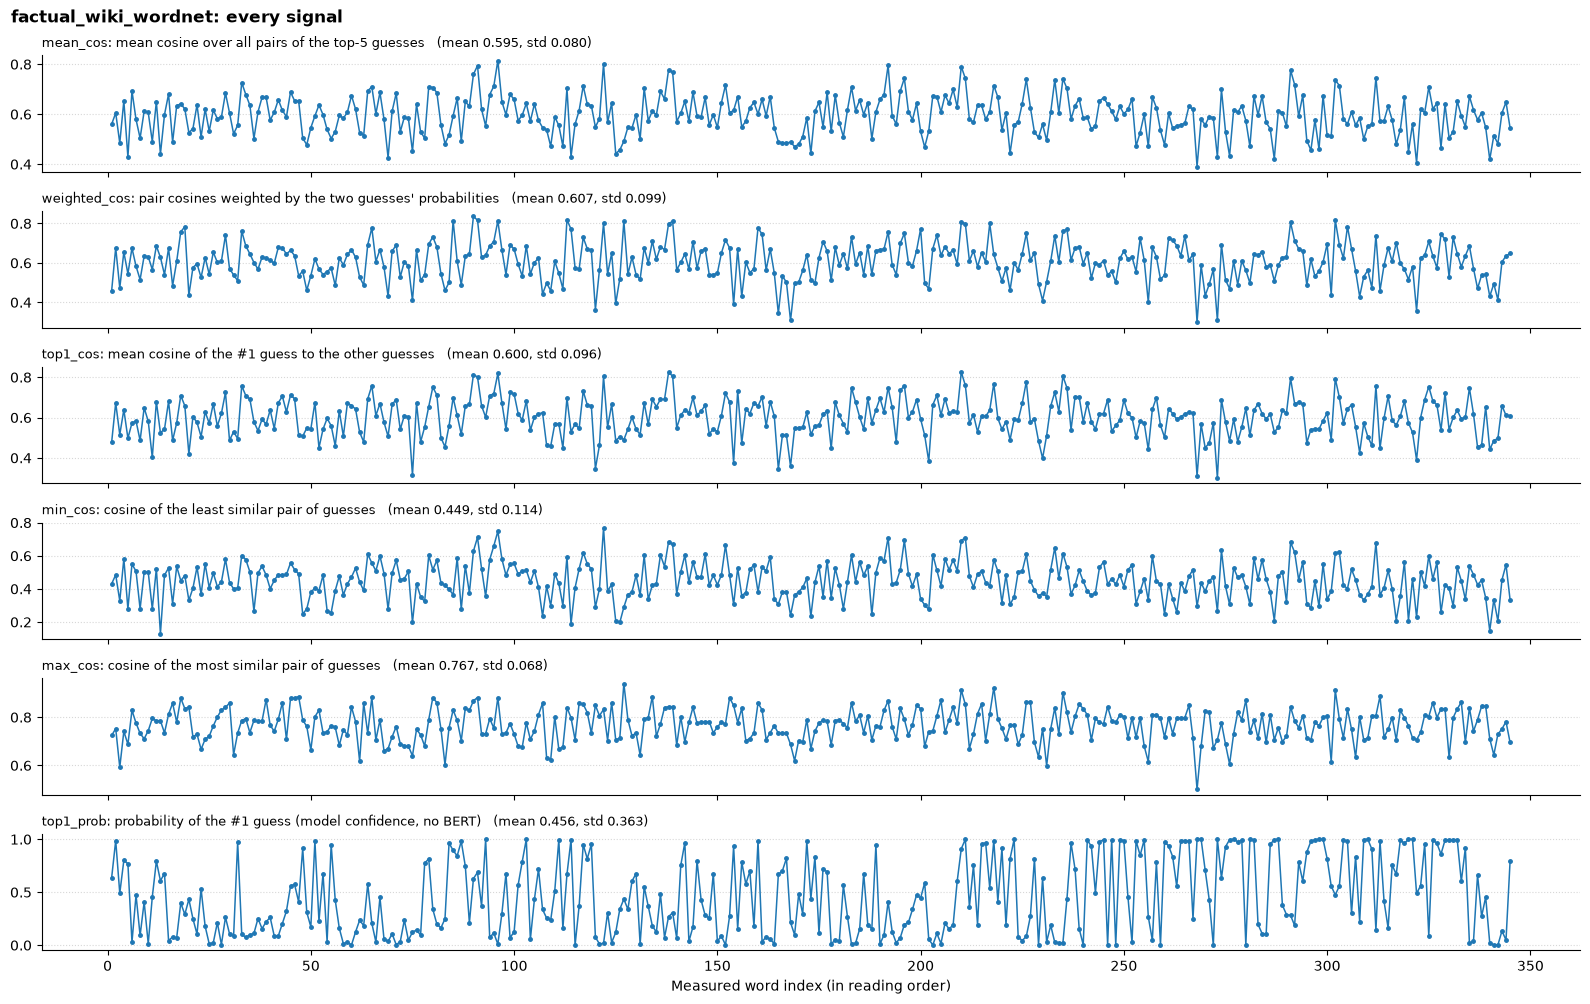

In [11]:
context_blocks, blocks_cosine_result, word_table = run_text("factual_wiki_wordnet")

_Dealer:_ "Pedigree? I should just think 'e is, Mum. Why, if the animal could only talk 'e wouldn't speak to either of us." _Small Bridesmaid_ (_loudly, in middle of ceremony_): "Mummie, are we all getting married?" _Small Girl:_ "To-day's my mummy's wedding-day." _Smaller Girl_ (_with air of superiority_): "_My_ mummy was married _years_ ago." "Wot's a minimum wage, Albert?" "Wot yer gets for goin' to yer work. If yer wants ter make a bit more yer does a bit o' work for it." _Office Boy_ (_anxious to go to football match_): "May I have the afternoon off, Sir? My grand----" _Employer:_ "Oh, yes, I've heard that before. Your grandmother died last week." _Office Boy:_ "Yes, Sir; but--my grandfather's getting married again this afternoon." _Minister's Wife:_ "My husband was asking only this morning why you weren't in the habit of attending church." _Latest Inhabitant:_ "Well, you see, it does so cut into one's Sundays." "Two mistakes here, waiter--one in your favor, one in mine." "In _you

,mean_cos,weighted_cos,top1_cos,min_cos,max_cos,top1_prob
count,215.000,215.000,215.000,215.000,215.000,215.000
mean,0.628,0.638,0.638,0.496,0.774,0.174
std,0.077,0.085,0.088,0.104,0.077,0.222
min,0.422,0.379,0.391,0.184,0.562,0.000
max,0.850,0.851,0.866,0.802,0.940,0.965


,word_idx,block,word,candidates,candidate_probs,pair_cosines,mean_cos,weighted_cos,top1_cos,min_cos,max_cos,top1_prob
0,1,1,"""Pedigree?",good hello welcome yes exc,0.0454102 0.0275879 0.0167236 0.0108032 0.0108032,good-hello:0.49 good-welcome:0.51 good-yes:0.59 good-exc:0.39 hell...,0.4832,0.4980,0.4940,0.3509,0.6406,0.045410
1,6,2,'e,twice back n differently god,0.00213623 0.00147247 0.00122833 0.00108337 0.000984192,twice-back:0.56 twice-n:0.47 twice-differently:0.53 twice-god:0.44...,0.5384,0.5353,0.5020,0.4413,0.6632,0.002136
2,8,2,Mum.,sir eh indeed somehow er,0.00872803 0.00411987 0.00386047 0.00363159 0.00340271,sir-eh:0.64 sir-indeed:0.47 sir-somehow:0.59 sir-er:0.56 eh-indeed...,0.5442,0.5528,0.5657,0.4367,0.6750,0.008728
3,12,3,animal,sum function number equation product,0.0289307 0.0240479 0.0186768 0.0164795 0.012085,sum-function:0.64 sum-number:0.65 sum-equation:0.61 sum-product:0....,0.6483,0.6461,0.6434,0.6134,0.6853,0.028931
4,15,3,talk,move see eat live walk,0.177734 0.0612793 0.0478516 0.0371094 0.0308838,move-see:0.64 move-eat:0.75 move-live:0.54 move-walk:0.77 see-eat:...,0.6497,0.6599,0.6748,0.5229,0.7845,0.177734
5,16,3,'e,back english human instead using,0.000166893 0.00014782 0.000114918 7.86781e-05 6.96182e-05,back-english:0.50 back-human:0.48 back-instead:0.49 back-using:0.5...,0.4679,0.4808,0.5116,0.2994,0.5854,0.000167
6,18,3,speak,eat want understand need act,0.0446777 0.0145264 0.012085 0.0106201 0.00732422,eat-want:0.74 eat-understand:0.78 eat-need:0.73 eat-act:0.57 want-...,0.6907,0.7186,0.7067,0.5196,0.8792,0.044678
7,20,3,either,humans people man ya human,0.0217285 0.0180664 0.00933838 0.00643921 0.00427246,humans-people:0.77 humans-man:0.62 humans-ya:0.51 humans-human:0.8...,0.6595,0.6842,0.6818,0.4877,0.8275,0.021729
8,24,4,Bridesmaid_,int size object font number,0.0217285 0.00799561 0.00662231 0.00582886 0.00454712,int-size:0.68 int-object:0.70 int-font:0.54 int-number:0.63 size-o...,0.6381,0.6425,0.6359,0.5366,0.8055,0.021729
9,25,4,"(_loudly,",dress wedding dresses b g,0.0236816 0.0111694 0.00634766 0.00436401 0.00205994,dress-wedding:0.80 dress-dresses:0.80 dress-b:0.56 dress-g:0.69 we...,0.6413,0.7111,0.7141,0.3965,0.7994,0.023682


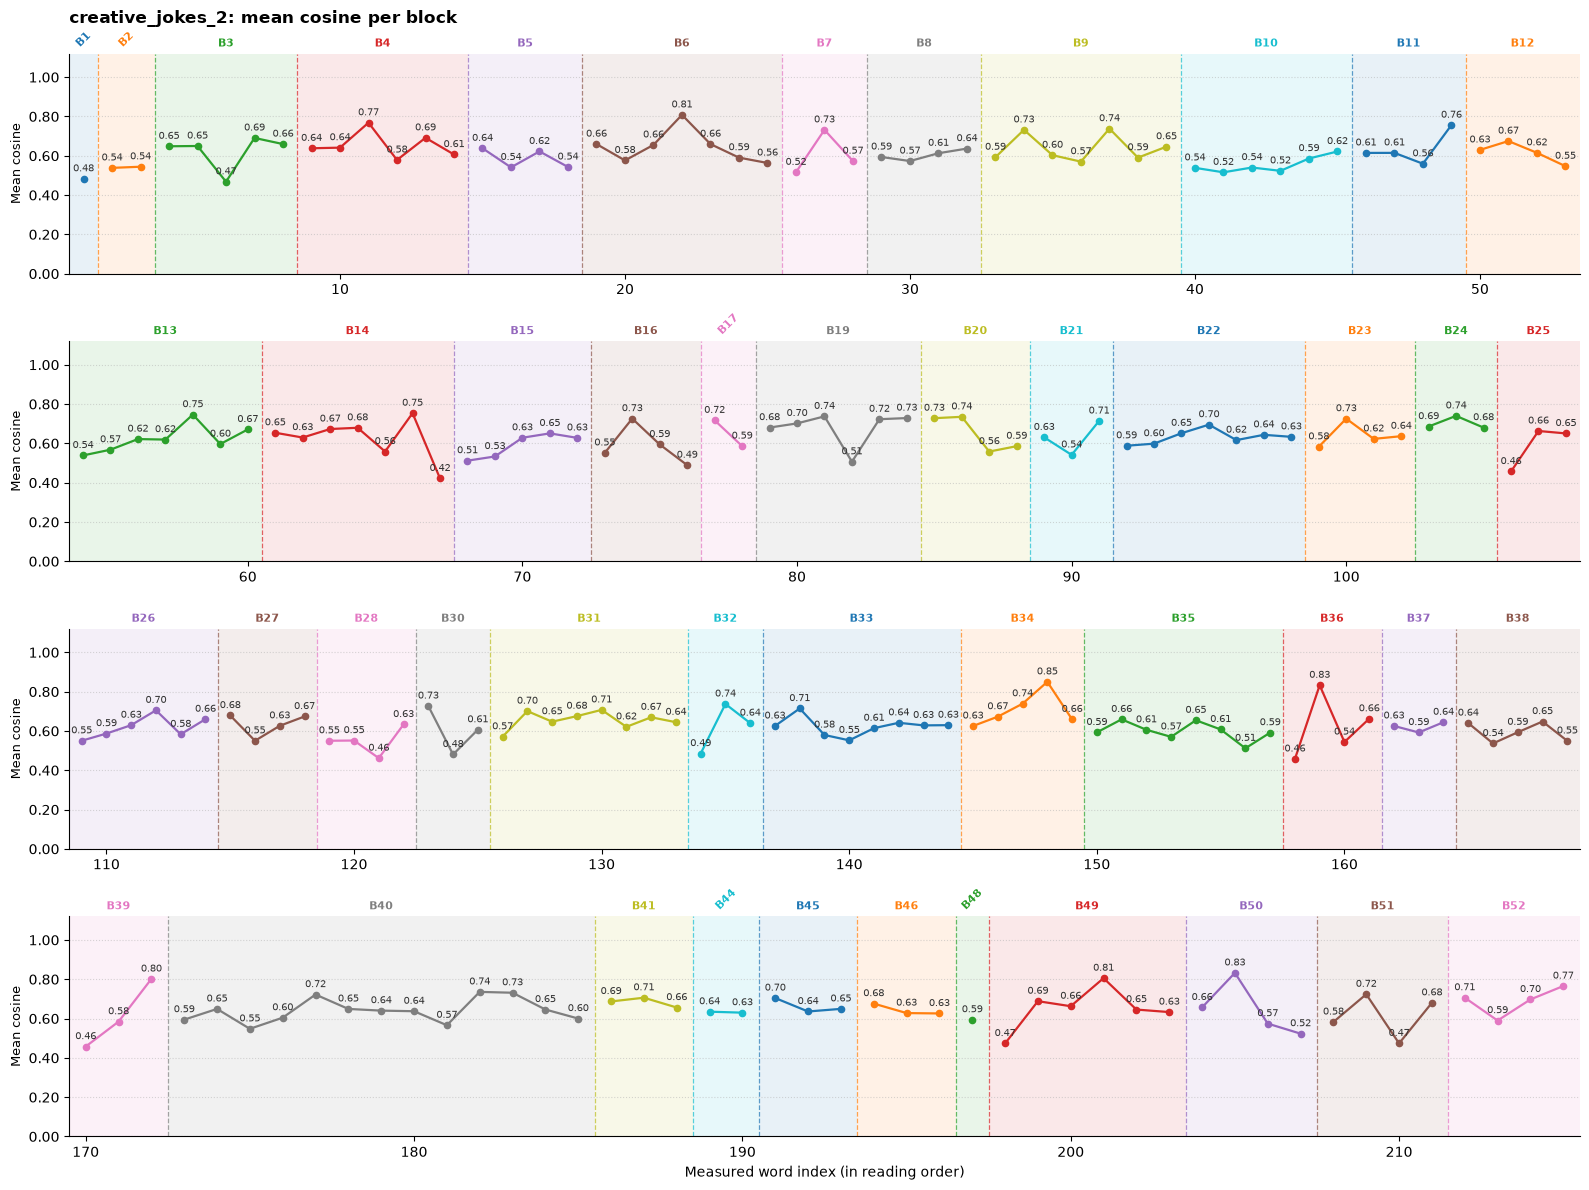

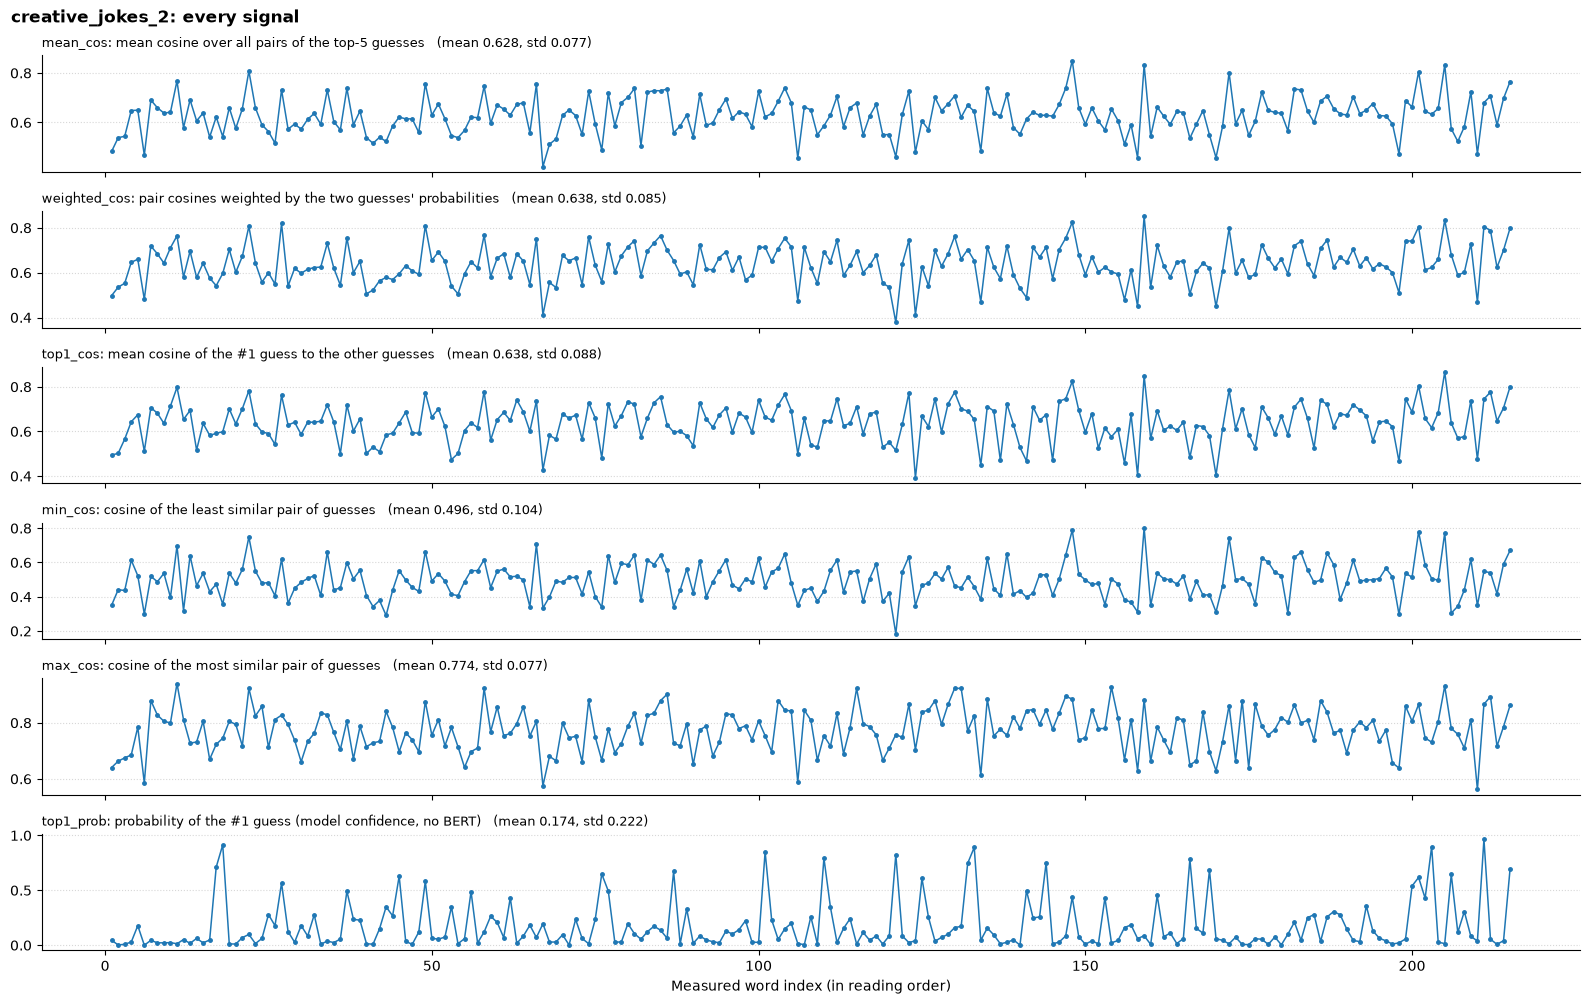

In [12]:
context_blocks, blocks_cosine_result, word_table = run_text("creative_jokes_2")

## BERT mean cosine: clusters and curves of the 25 texts

The 25 texts' BERT mean cosine curves (`src/Results_CSV/cosine`) are split into 2 clusters (DTW between raw curves,
k-medoids, as in `Qwen7B/analysis/cluster.py`). Each text is a dot on the map: colour = its real kind, filled / hollow =
its cluster, black ring = cluster centre, bold name = sitting in the other kind's cluster.

For comparison only, the same clustering is also run on the curves of the Qwen7B run (GloVe top 5, LCA likely top 3
(10%), surprisal per word, from `Qwen7B/results/run`) and every measurement is ranked in one table.

In [30]:
# Clustering code and saved results of the Qwen7B pipeline
import sys

QWEN_DIR = Path.cwd() / "Qwen7B"            # this notebook runs from src/note_books
if str(QWEN_DIR) not in sys.path:
    sys.path.insert(0, str(QWEN_DIR))

from analysis.cluster import cluster, score, text_map
from analysis.figures import KIND_COLORS, plot_text_map, short_name
from analysis.signals import curves_of, dataset_names, kinds_of, load_tables, signal_by_key
from config.qwen_config import MODEL_NAME

BERT_COLUMN = "mean_cos"                     # the column of Results_CSV/cosine that is clustered and drawn
BERT_NAME = "BERT mean cosine"
COMPARE_WITH = ["glove_top5", "lca_likely_top3_10pct", "surprisal_per_word"]   # only for the ranking table

In [31]:
# The curves of every text (read from the CSVs)
names = list(dataset_names())                 # the 25 texts of Qwen7B/texts
kinds = list(kinds_of(names))

missing = [n for n in names if not results_path(n).exists()]
if missing:
    raise FileNotFoundError(f"no cosine CSV yet for: {', '.join(missing)} (run run_text on them first)")

measurement_curves = {BERT_NAME: [signal_curve(load_word_table(n), BERT_COLUMN) for n in names]}

qwen_words, qwen_tokens = load_tables(names, MODEL_NAME)    # Qwen7B/results/run/words + tokens
for key in COMPARE_WITH:
    signal = signal_by_key(key)
    measurement_curves[signal.name] = curves_of(signal, names, qwen_words, qwen_tokens)

for measurement, curves in measurement_curves.items():
    lengths = [len(c) for c in curves]
    print(f"{measurement}: {len(curves)} texts, {min(lengths)}-{max(lengths)} points each")

BERT mean cosine: 25 texts, 215-402 points each
GloVe distance, top 5 guesses: 25 texts, 128-259 points each
LCA height, likely guesses, at most 3 (10%): 25 texts, 128-259 points each
surprisal per word: 25 texts, 128-259 points each


In [32]:
# Cluster the 25 texts on every measurement (BERT is drawn below; the others are only for the ranking table)
cluster_results = {}
for measurement, curves in measurement_curves.items():
    labels, centres, table = cluster(curves)
    cluster_results[measurement] = dict(labels=labels, centres=centres, table=table,
                                        result=score(names, kinds, labels))
r = cluster_results[BERT_NAME]["result"]
print(f"{BERT_NAME}: {r['correct']} of {r['texts']} texts sit with their own kind")

BERT mean cosine: 22 of 25 texts sit with their own kind


/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


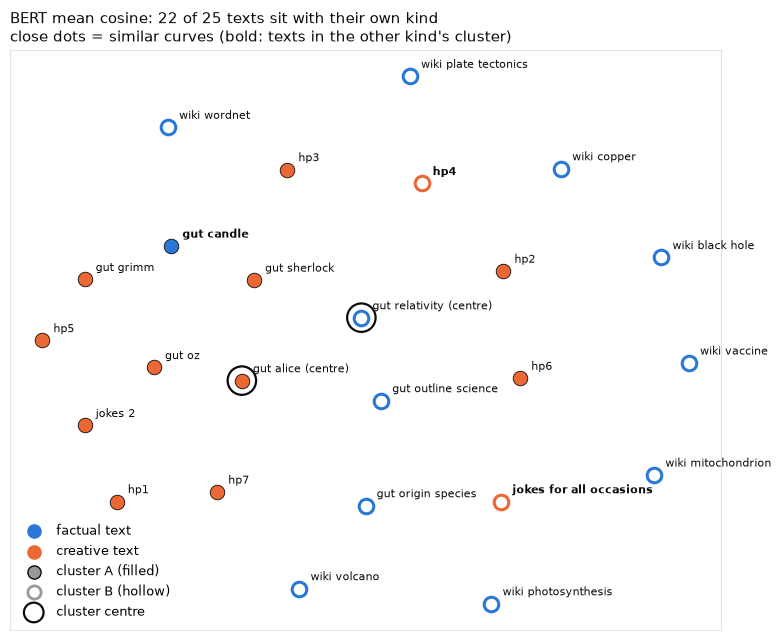

In [33]:
# BERT mean cosine: the text map (every text is a dot, close dots = similar curves)
bert = cluster_results[BERT_NAME]
plot_text_map(BERT_NAME, text_map(bert["table"]), names, kinds, bert["labels"], bert["centres"])
plt.show()

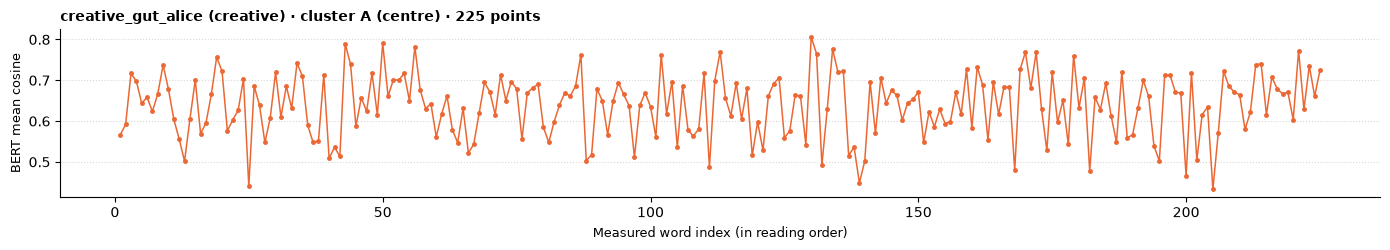

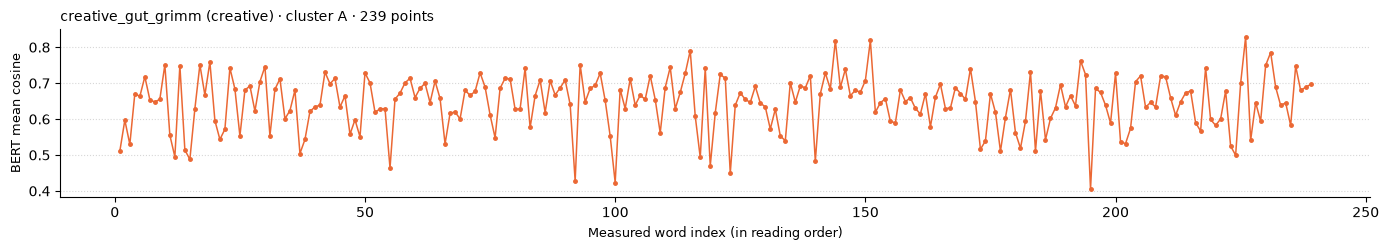

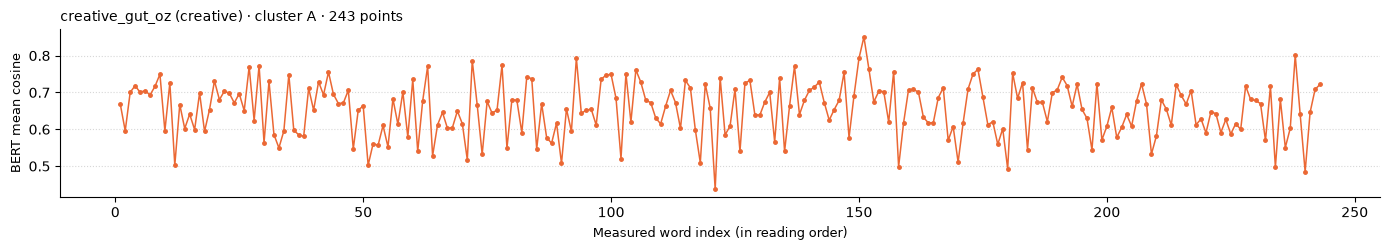

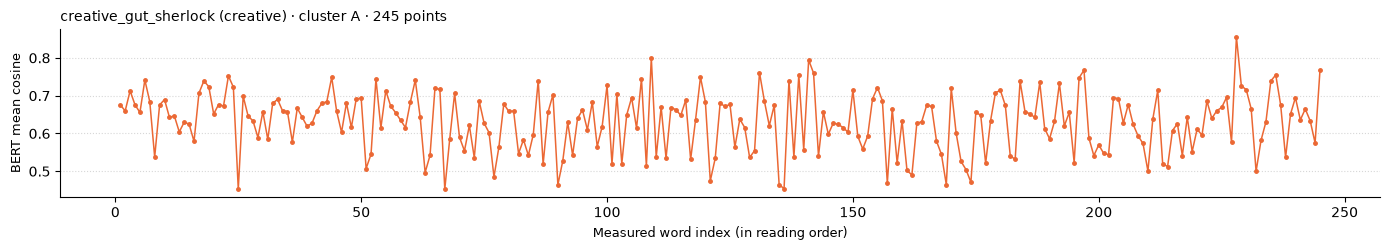

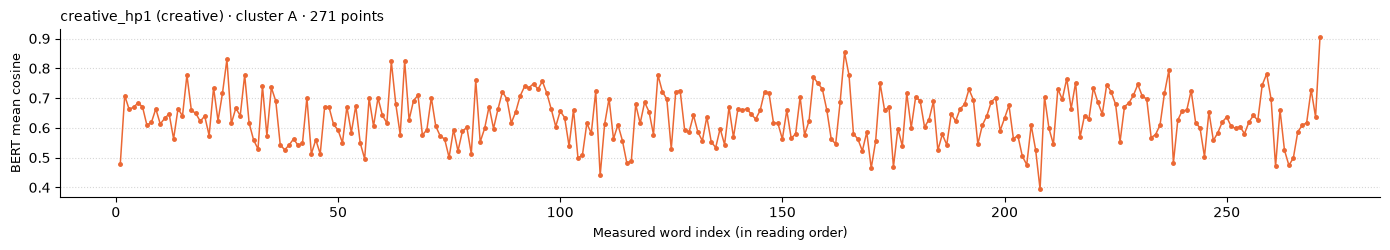

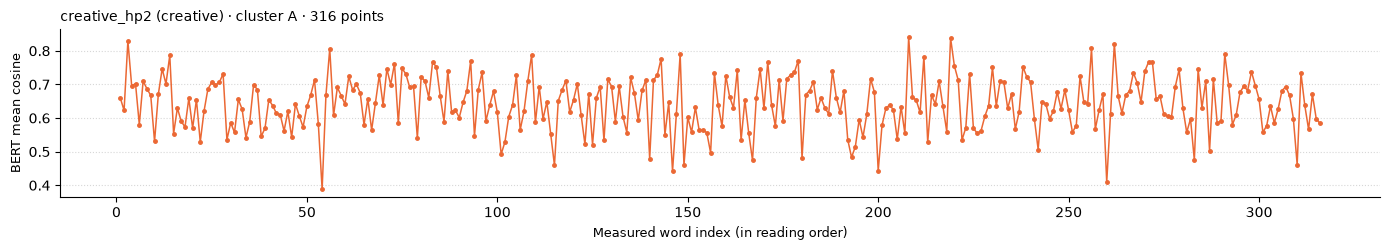

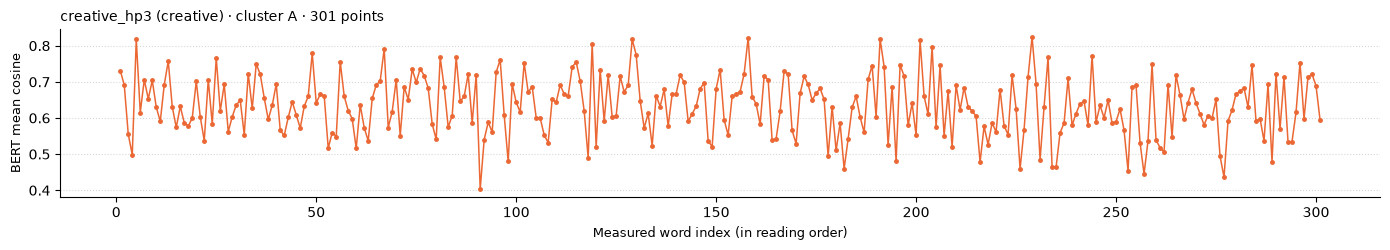

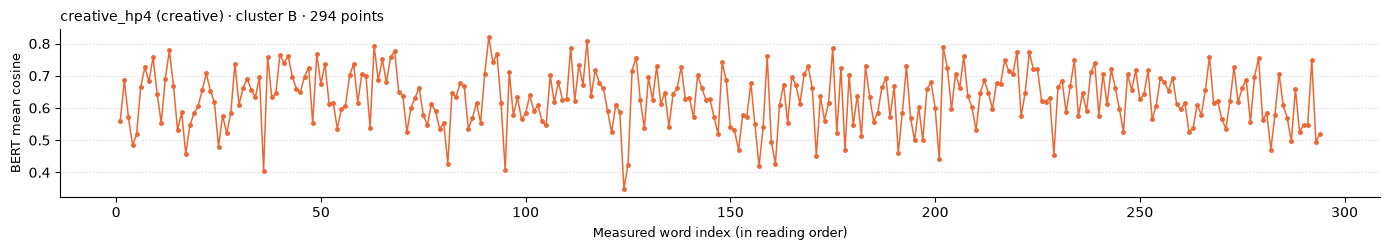

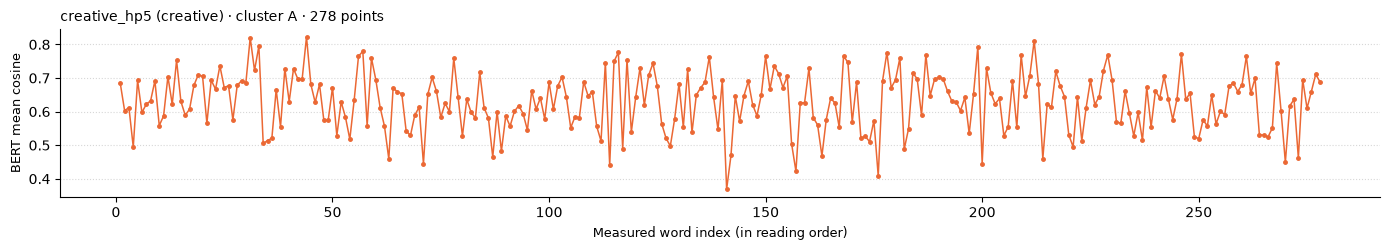

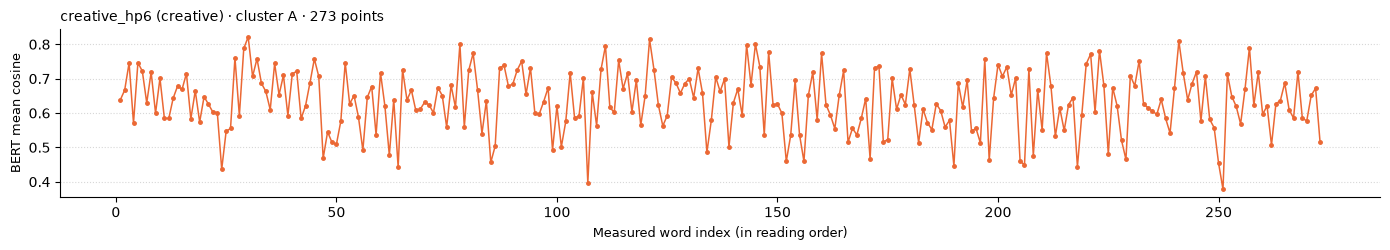

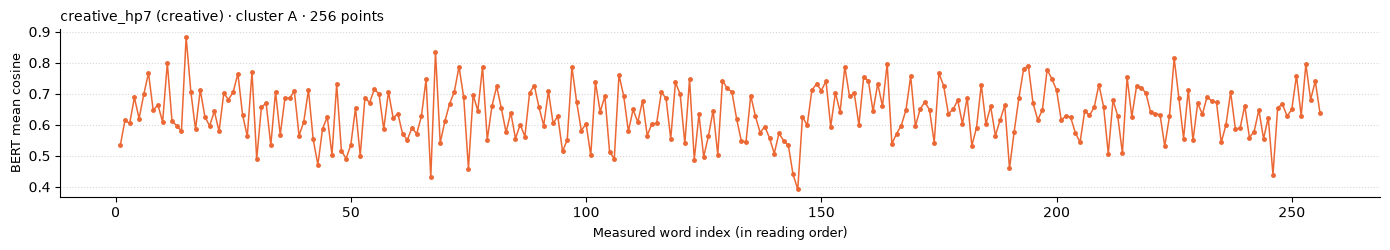

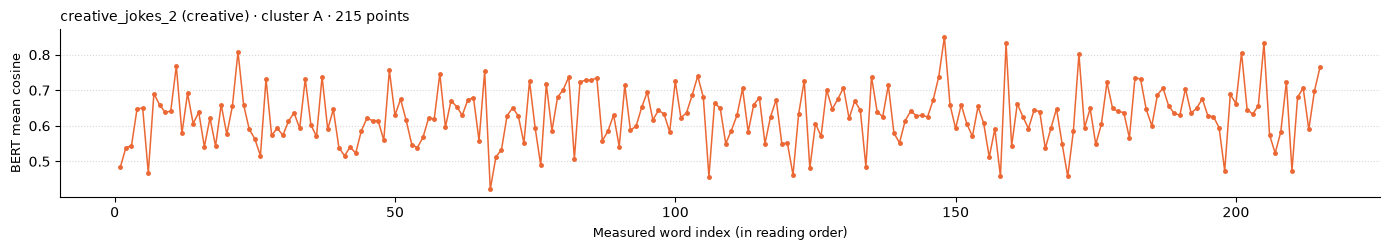

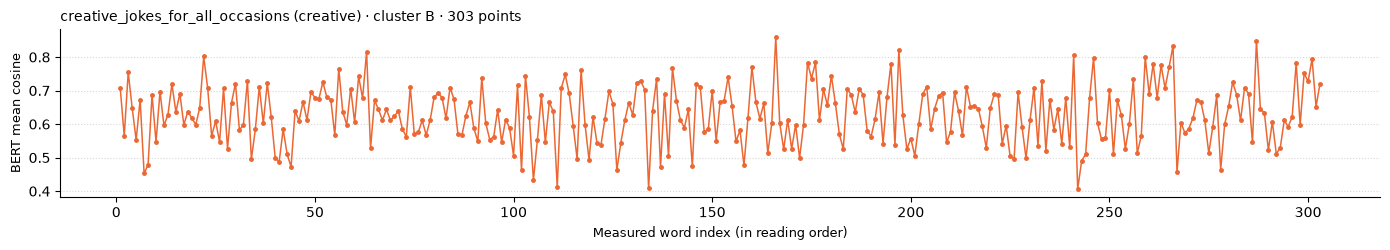

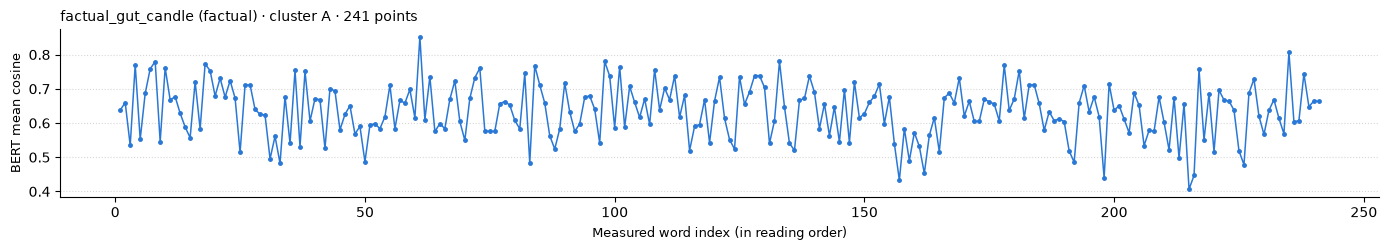

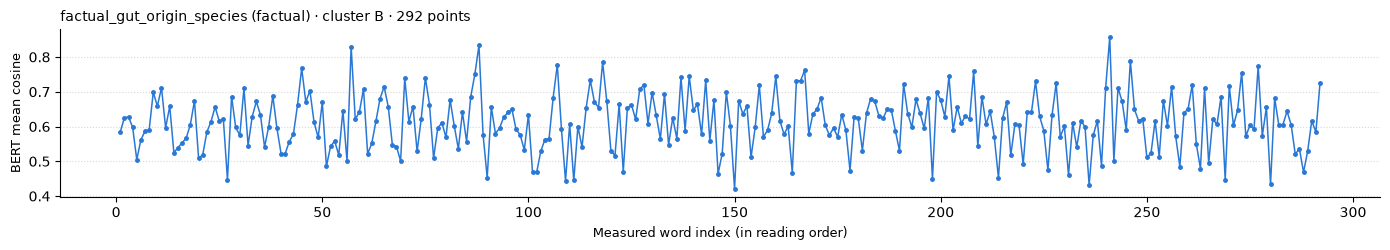

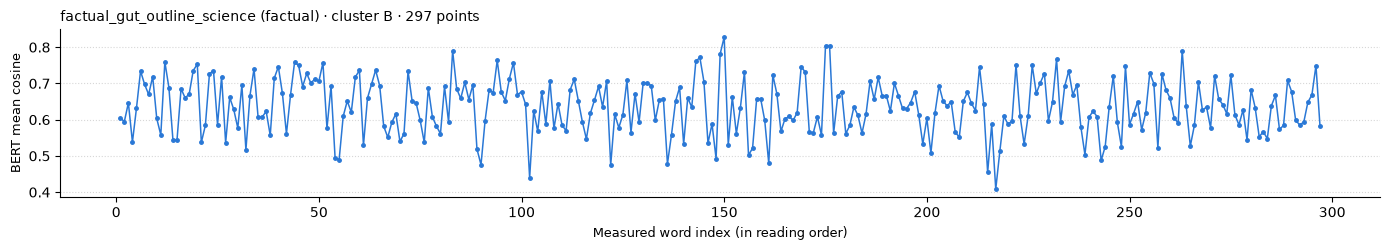

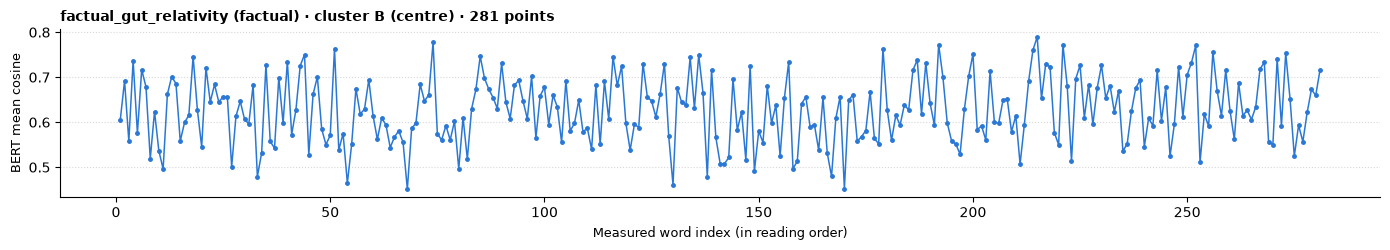

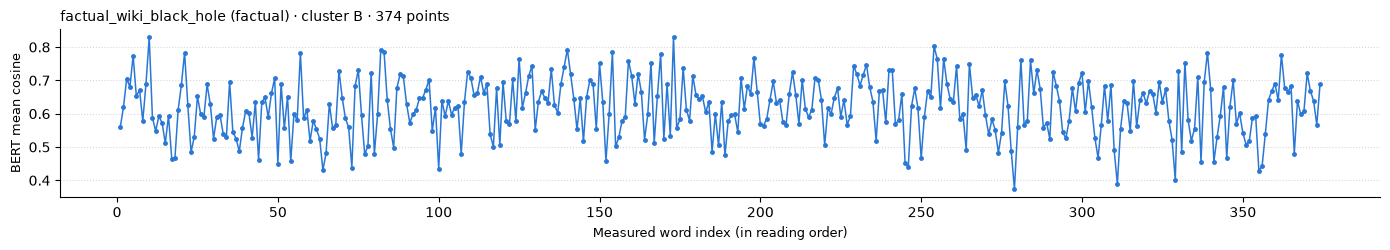

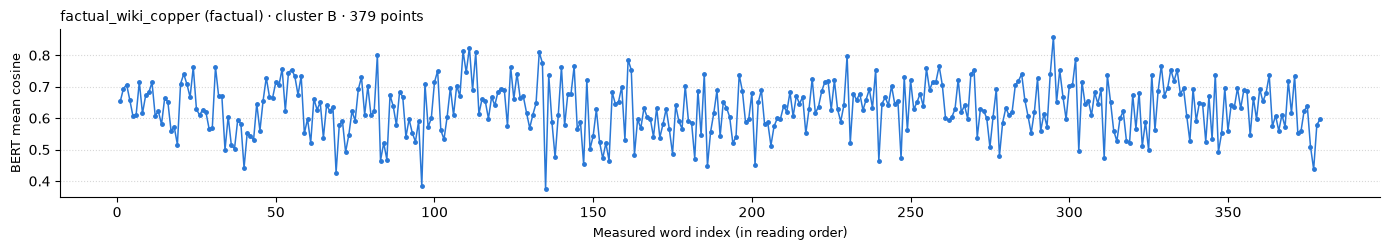

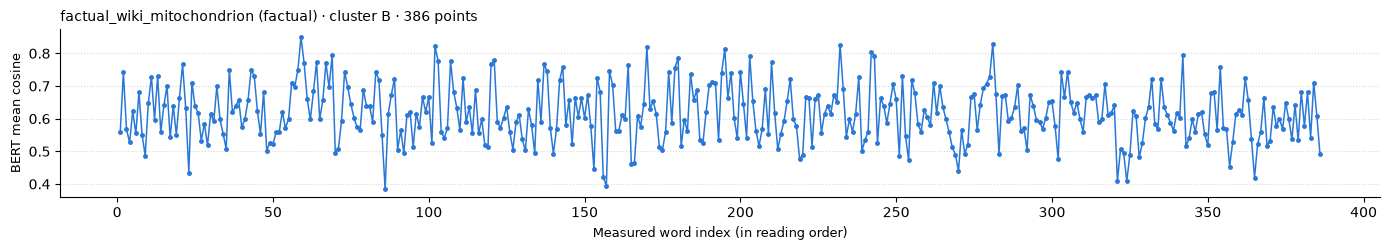

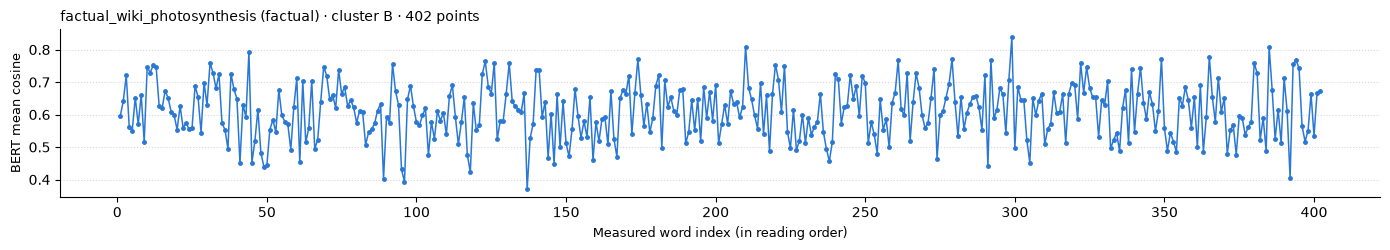

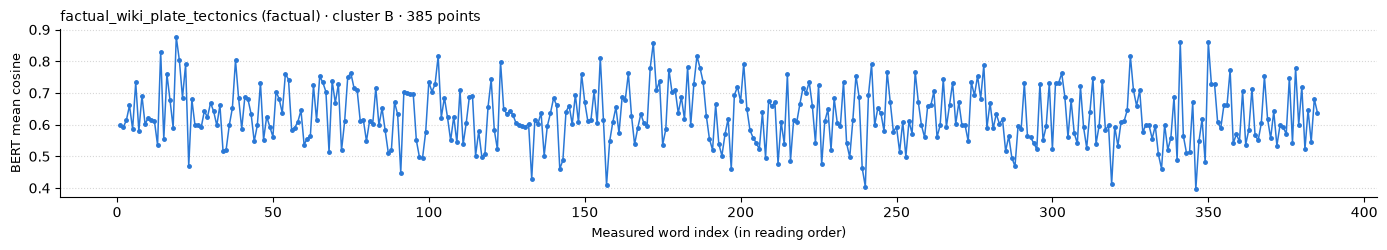

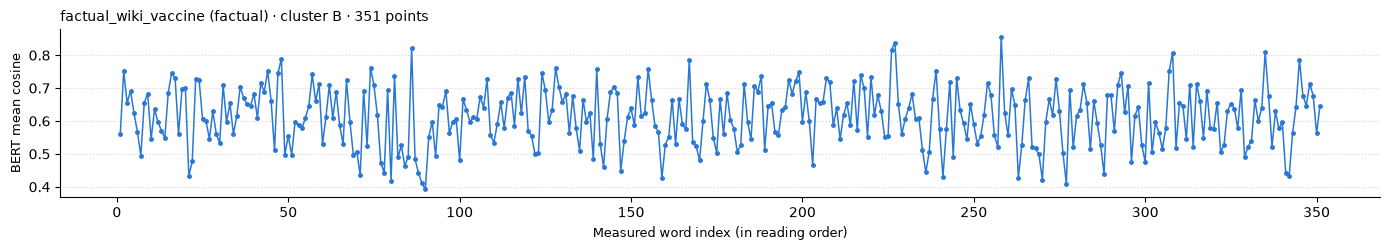

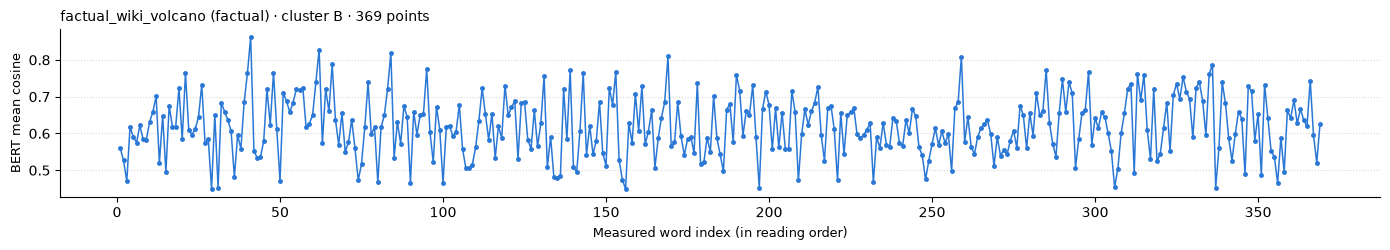

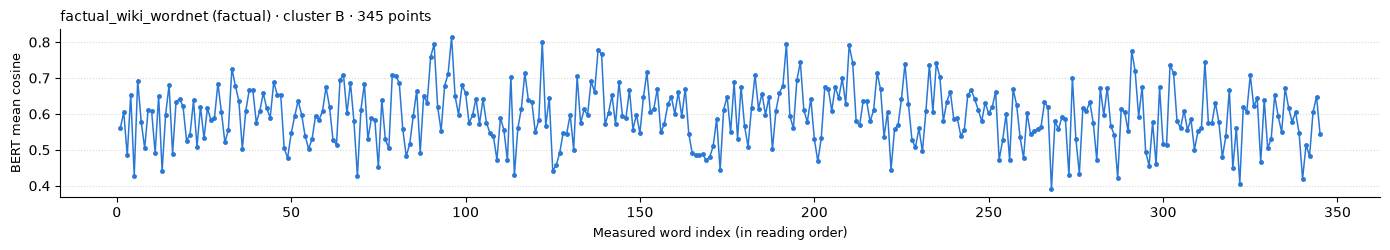

In [34]:
# BERT mean cosine: every text's curve, each in its own full-width graph
bert = cluster_results[BERT_NAME]
for index, values in enumerate(measurement_curves[BERT_NAME]):
    is_centre = index in bert["centres"]
    fig, ax = plt.subplots(figsize=(14, 2.6))
    ax.plot(np.arange(1, len(values) + 1), values, color=KIND_COLORS[kinds[index]], lw=1.1, marker="o", ms=2.5)
    title = (f"{names[index]} ({kinds[index]}) · cluster {'AB'[bert['labels'][index]]}"
             f"{' (centre)' if is_centre else ''} · {len(values)} points")
    ax.set_title(title, fontsize=10, loc="left", fontweight="bold" if is_centre else "normal")
    ax.set_ylabel(BERT_NAME, fontsize=9)
    ax.set_xlabel("Measured word index (in reading order)", fontsize=9)
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    plt.show()

In [35]:
# Every measurement ranked: how many of the 25 texts its clustering puts with their own kind (best on top)
rows = []
for measurement, c in cluster_results.items():
    result, centres = c["result"], c["centres"]
    rows.append({
        "measurement": measurement,
        "correct": result["correct"],
        "texts": result["texts"],
        "factual correct": f"{result['factual correct']}/{result['factual texts']}",
        "creative correct": f"{result['creative correct']}/{result['creative texts']}",
        "wrong cluster": result["wrong cluster"],
        "centre texts": f"{names[centres[0]]}, {names[centres[1]]}",
    })

ranking = pd.DataFrame(rows).sort_values("correct", ascending=False, kind="stable", ignore_index=True)
ranking.insert(0, "rank", ranking["correct"].rank(ascending=False, method="min").astype(int))
ranking_path = RESULTS_DIR / "measurements_ranked.csv"
ranking.to_csv(ranking_path, index=False)
print(f"saved -> {ranking_path}")
with pd.option_context("display.max_colwidth", 100):
    display(ranking)

saved -> /app/src/Results_CSV/cosine/measurements_ranked.csv


,rank,measurement,correct,texts,factual correct,creative correct,wrong cluster,centre texts
0,1,"GloVe distance, top 5 guesses",23,25,10/12,13/13,"factual_gut_candle, factual_wiki_vaccine","factual_gut_candle, factual_gut_outline_science"
1,1,"LCA height, likely guesses, at most 3 (10%)",23,25,10/12,13/13,"factual_wiki_black_hole, factual_wiki_copper","creative_gut_oz, factual_wiki_volcano"
2,3,BERT mean cosine,22,25,11/12,11/13,"creative_hp4, creative_jokes_for_all_occasions, factual_gut_candle","creative_gut_alice, factual_gut_relativity"
3,3,surprisal per word,22,25,11/12,11/13,"creative_hp4, creative_jokes_for_all_occasions, factual_gut_outline_science","creative_jokes_2, factual_gut_origin_species"
